=== 1. VERİ SETİ GENEL BİLGİLERİ ===
Satır ve Sütun Sayısı: (10000, 16)

Sütun İsimleri:
['ID', 'Age', 'Gender', 'Country', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'Sleep_Quality', 'BMI', 'Heart_Rate', 'Stress_Level', 'Physical_Activity_Hours', 'Health_Issues', 'Occupation', 'Smoking', 'Alcohol_Consumption']

Eksik Veri Sayısı:
Health_Issues    5941
dtype: int64

=== 2. TANIMLAYICI İSTATİSTİKLER ===


,ID,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0,10000.00
mean,5000.50,34.95,2.51,238.41,6.64,23.99,70.62,7.49,0.2,0.30
std,2886.90,11.16,1.45,137.75,1.22,3.91,9.82,4.32,0.4,0.46
min,1.00,18.00,0.00,0.00,3.00,15.00,50.00,0.00,0.0,0.00
25%,2500.75,26.00,1.50,138.75,5.80,21.30,64.00,3.70,0.0,0.00
50%,5000.50,34.00,2.50,235.40,6.60,24.00,71.00,7.50,0.0,0.00
75%,7500.25,43.00,3.50,332.02,7.50,26.60,77.00,11.20,0.0,1.00
max,10000.00,80.00,8.20,780.30,10.00,38.20,109.00,15.00,1.0,1.00



=== 3. KORELASYON VE HİPOTEZ TESTLERİ ===
[H1 Testi] Caffeine_mg vs Sleep_Hours:
   Pearson r = -0.1905, p-değeri = 2.3671e-82
   Spearman rho = -0.1902, p-değeri = 4.0941e-82

[Kalp Sağlığı] Caffeine_mg vs Heart_Rate:
   Pearson r = 0.0600, p-değeri = 1.8856e-09

[H2 Testi] Stres Düzeyine Göre Kafein Farkı (Kruskal-Wallis):
   H-istatistiği = 221.9327, p-değeri = 6.4259e-49


/tmp/ipykernel_362/764309761.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=stress_col, y=caffeine_col, data=df, palette="Set2", ax=axes[2])


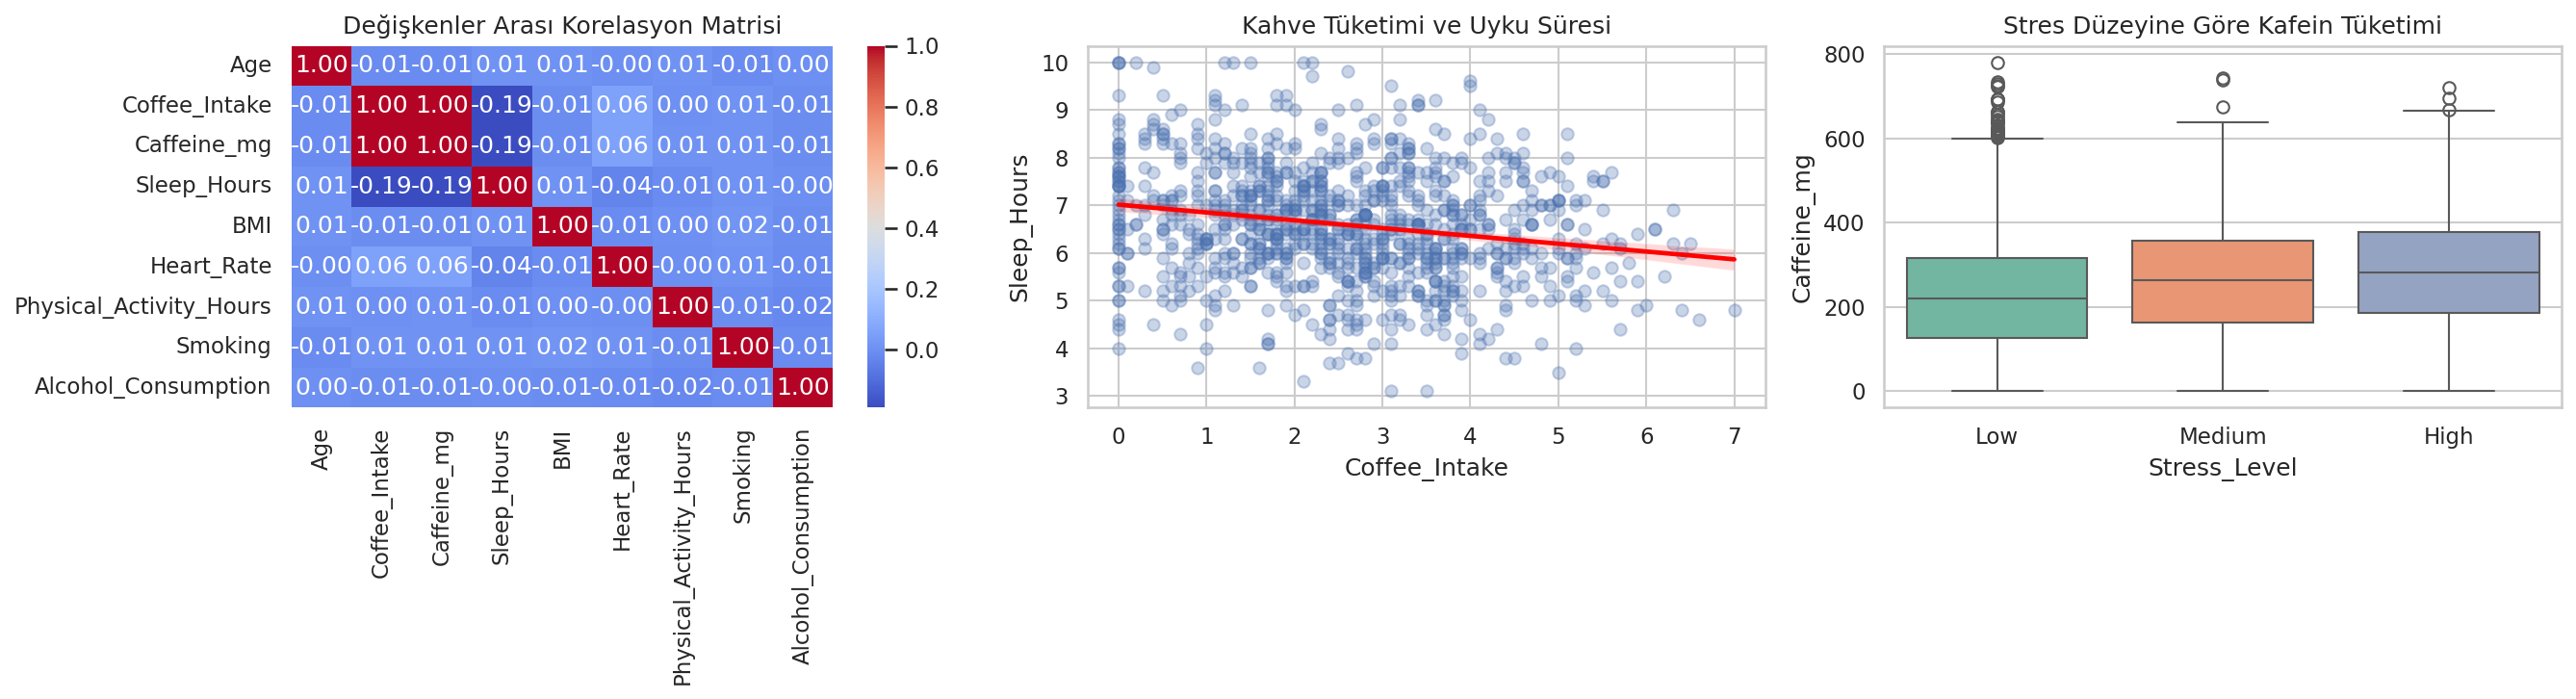

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Görsel ayarlar
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150

# 1. Veri Setini Yükleme
df = pd.read_csv("synthetic_coffee_health_10000.csv")

print("=== 1. VERİ SETİ GENEL BİLGİLERİ ===")
print(f"Satır ve Sütun Sayısı: {df.shape}")
print("\nSütun İsimleri:")
print(list(df.columns))
print("\nEksik Veri Sayısı:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() > 0 else "Eksik veri bulunmamaktadır.")

# Sütun isimlerini küçük harfe çevirip esnek eşleştirme yapalım
cols = {c.lower().strip(): c for c in df.columns}
coffee_col = next((cols[k] for k in cols if "coffee" in k or "cup" in k or "caffeine" in k), None)
caffeine_col = next((cols[k] for k in cols if "caffeine" in k), coffee_col)
sleep_col = next((cols[k] for k in cols if "sleep_hour" in k or "sleep_duration" in k or "sleep" in k), None)
sleep_qual_col = next((cols[k] for k in cols if "sleep_quality" in k or "quality" in k), None)
stress_col = next((cols[k] for k in cols if "stress" in k), None)
hr_col = next((cols[k] for k in cols if "heart" in k or "bpm" in k), None)

print("\n=== 2. TANIMLAYICI İSTATİSTİKLER ===")
display(df.describe().round(2))

# 3. İstatistiksel Hipotez Testleri ve Korelasyon
print("\n=== 3. KORELASYON VE HİPOTEZ TESTLERİ ===")
if caffeine_col and sleep_col:
    r_sleep, p_sleep = stats.pearsonr(df[caffeine_col].dropna(), df[sleep_col].dropna())
    rho_sleep, p_rho_sleep = stats.spearmanr(df[caffeine_col].dropna(), df[sleep_col].dropna())
    print(f"[H1 Testi] {caffeine_col} vs {sleep_col}:")
    print(f"   Pearson r = {r_sleep:.4f}, p-değeri = {p_sleep:.4e}")
    print(f"   Spearman rho = {rho_sleep:.4f}, p-değeri = {p_rho_sleep:.4e}")

if caffeine_col and hr_col:
    r_hr, p_hr = stats.pearsonr(df[caffeine_col].dropna(), df[hr_col].dropna())
    print(f"\n[Kalp Sağlığı] {caffeine_col} vs {hr_col}:")
    print(f"   Pearson r = {r_hr:.4f}, p-değeri = {p_hr:.4e}")

if stress_col and caffeine_col:
    if df[stress_col].dtype == 'object':
        groups = [group[caffeine_col].dropna() for _, group in df.groupby(stress_col)]
        kw_stat, kw_p = stats.kruskal(*groups)
        print(f"\n[H2 Testi] Stres Düzeyine Göre Kafein Farkı (Kruskal-Wallis):")
        print(f"   H-istatistiği = {kw_stat:.4f}, p-değeri = {kw_p:.4e}")
    else:
        r_str, p_str = stats.pearsonr(df[caffeine_col].dropna(), df[stress_col].dropna())
        print(f"\n[H2 Testi] {caffeine_col} vs {stress_col}:")
        print(f"   Pearson r = {r_str:.4f}, p-değeri = {p_str:.4e}")

# 4. Grafikler (Word Raporu İçin)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik 1: Sayısal Değişkenler Korelasyon Isı Haritası
num_df = df.select_dtypes(include=[np.number]).drop(columns=["ID", "id"], errors="ignore")
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Değişkenler Arası Korelasyon Matrisi")

# Grafik 2: Kahve/Kafein ve Uyku Süresi İlişkisi
if coffee_col and sleep_col:
    if df[coffee_col].nunique() <= 15:
        sns.boxplot(x=coffee_col, y=sleep_col, data=df, palette="YlOrBr", ax=axes[1])
    else:
        sns.regplot(x=coffee_col, y=sleep_col, data=df.sample(min(1000, len(df))), scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, ax=axes[1])
    axes[1].set_title("Kahve Tüketimi ve Uyku Süresi")

# Grafik 3: Stres Düzeyi ve Kahve/Kafein Dağılımı
if stress_col and caffeine_col:
    sns.boxplot(x=stress_col, y=caffeine_col, data=df, palette="Set2", ax=axes[2])
    axes[2].set_title("Stres Düzeyine Göre Kafein Tüketimi")

plt.tight_layout()
plt.savefig("analiz_grafikleri.png", dpi=300)
plt.show()